# Sensitivities: Finite Differences vs Likelihood Ratio

Delta of an option with payoff $(S_T-K)^+\mathbf 1_{\{S_T\le 1.3K\}}$ in the Black-Scholes model, with $S_0 = K = 100$, $T = 2$, $r = 0.02$, $\sigma = 0.25$. Both methods are first checked on a plain call.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

S0 = K = 100.0
T, r, sigma = 2.0, 0.02, 0.25
B = 1.3 * K
M = 10_000
rng = np.random.default_rng(0)

def call_payoff(s):
    return np.maximum(s - K, 0.0)

def capped_payoff(s):
    return np.where(s <= B, np.maximum(s - K, 0.0), 0.0)

## Closed-form deltas

The capped payoff is a call struck at $K$, minus a call struck at $B$, minus $(B-K)$ times a digital paying $\mathbf 1_{\{S_T > B\}}$.

In [2]:
def d1(s, k):
    return (np.log(s / k) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

def call_delta(s, k):
    return norm.cdf(d1(s, k))

def digital_delta(s, k):
    return np.exp(-r * T) * norm.pdf(d1(s, k) - sigma * np.sqrt(T)) / (s * sigma * np.sqrt(T))

delta_call = call_delta(S0, K)
delta_capped = call_delta(S0, K) - call_delta(S0, B) - (B - K) * digital_delta(S0, B)
print(f"Call delta:   {delta_call:.4f}")
print(f"Capped delta: {delta_capped:.4f}")

Call delta:   0.6141
Capped delta: 0.0534


## Estimators

In [3]:
def summary(X):
    return X.mean(), 1.96 * X.std(ddof=1) / np.sqrt(len(X))

def finite_difference_delta(payoff, eps, rng):
    G = rng.standard_normal(M)
    growth = np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * G)
    up, down = payoff(S0 * (1 + eps) * growth), payoff(S0 * (1 - eps) * growth)
    return summary(np.exp(-r * T) * (up - down) / (2 * eps * S0))

def likelihood_ratio_delta(payoff, rng):
    G = rng.standard_normal(M)
    S_T = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * G)
    return summary(np.exp(-r * T) * payoff(S_T) * G / (S0 * sigma * np.sqrt(T)))

In [4]:
eps_list = [0.001, 0.01, 0.05, 0.1, M**(-1 / 5), 0.3]

for name, payoff, exact in [("Call", call_payoff, delta_call), ("Capped call", capped_payoff, delta_capped)]:
    print(f"{name}, exact delta = {exact:.4f}")
    for eps in eps_list:
        est, ci = finite_difference_delta(payoff, eps, rng)
        print(f"  finite differences, eps = {eps:.4f}: {est:.4f} ± {ci:.4f}")
    est, ci = likelihood_ratio_delta(payoff, rng)
    print(f"  likelihood ratio:                  {est:.4f} ± {ci:.4f}")

Call, exact delta = 0.6141
  finite differences, eps = 0.0010: 0.6174 ± 0.0133
  finite differences, eps = 0.0100: 0.6126 ± 0.0133
  finite differences, eps = 0.0500: 0.6155 ± 0.0131
  finite differences, eps = 0.1000: 0.6145 ± 0.0129
  finite differences, eps = 0.1585: 0.6047 ± 0.0124
  finite differences, eps = 0.3000: 0.5850 ± 0.0114
  likelihood ratio:                  0.6014 ± 0.0304
Capped call, exact delta = 0.0534
  finite differences, eps = 0.0010: 0.0850 ± 0.1058
  finite differences, eps = 0.0100: 0.0679 ± 0.0352
  finite differences, eps = 0.0500: 0.0431 ± 0.0161
  finite differences, eps = 0.1000: 0.0497 ± 0.0102
  finite differences, eps = 0.1585: 0.0594 ± 0.0066
  finite differences, eps = 0.3000: 0.0456 ± 0.0031
  likelihood ratio:                  0.0545 ± 0.0026


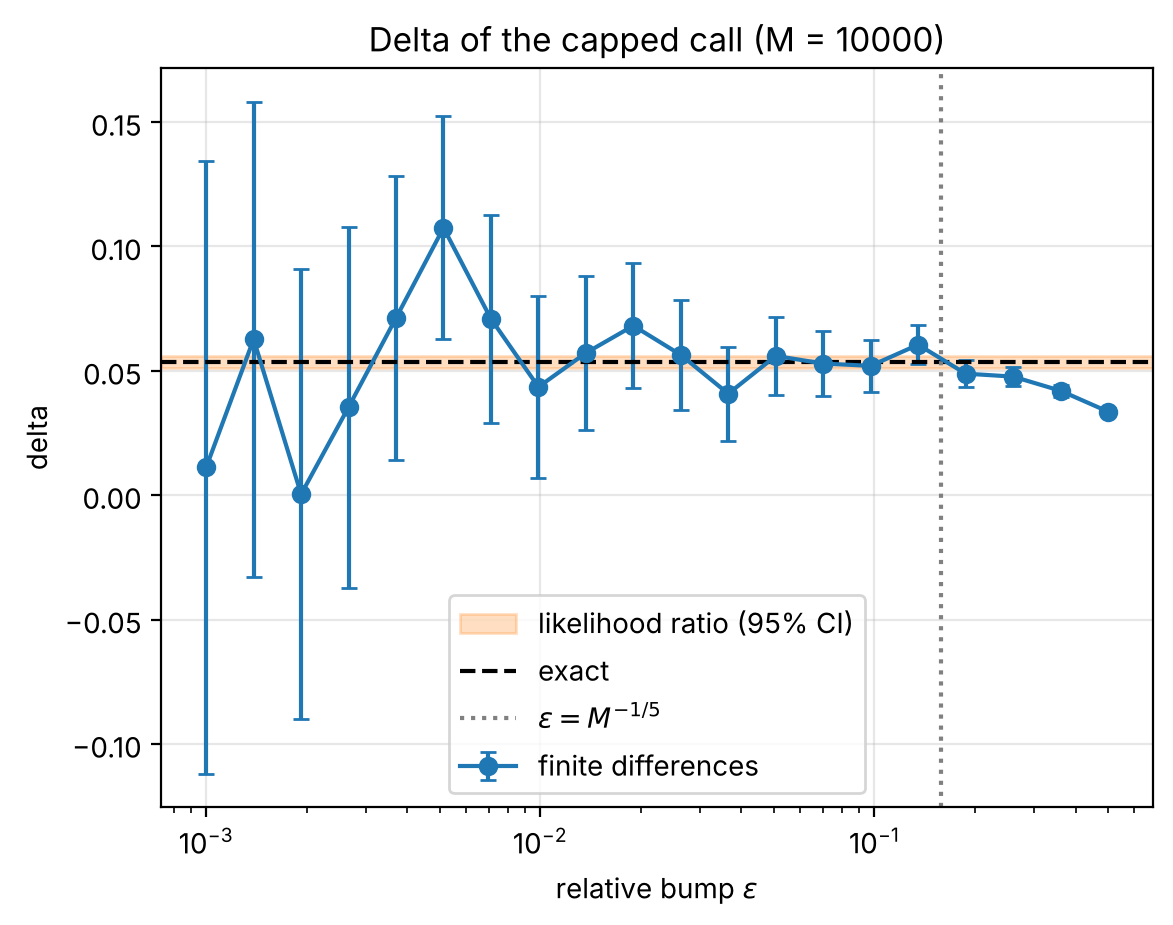

In [5]:
eps_grid = np.logspace(-3, np.log10(0.5), 20)
fd = np.array([finite_difference_delta(capped_payoff, eps, rng) for eps in eps_grid])
lr = likelihood_ratio_delta(capped_payoff, rng)

plt.errorbar(eps_grid, fd[:, 0], yerr=fd[:, 1], fmt="o-", capsize=3, label="finite differences")
plt.axhspan(lr[0] - lr[1], lr[0] + lr[1], color="tab:orange", alpha=0.25, label="likelihood ratio (95% CI)")
plt.axhline(delta_capped, color="k", ls="--", label="exact")
plt.axvline(M**(-1 / 5), color="grey", ls=":", label=r"$\varepsilon = M^{-1/5}$")
plt.xscale("log"); plt.xlabel(r"relative bump $\varepsilon$"); plt.ylabel("delta")
plt.title(f"Delta of the capped call (M = {M})")
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

The payoff is discontinuous at $B$, so the finite difference variance grows like $1/\varepsilon$ while the bias grows like $\varepsilon^2$; balancing the two gives $\varepsilon \propto M^{-1/5}$. The likelihood ratio estimator does not differentiate the payoff and is unbiased.